In [1]:
import logging
logging.captureWarnings(True)

In [2]:
import numpy as np
import networkx as nx

In [3]:
from multifractal_networks.mfng import MultifractalNetworkGenerator
from multifractal_networks.mfnf import MultifractalNetworkFitter

# Generating the network

In [4]:
N = 10000
m = 3
k = 4

In [5]:
P = np.array([
    [0.28496249, 0.46450071, 0.3449749 ],
    [0.46450071, 0.00946877, 0.39117118],
    [0.34497490, 0.39117118, 0.05582052]
])
l = np.array(
    [0.08283585, 0.59124287, 0.32592127]
)

In [6]:
generator = MultifractalNetworkGenerator(P,l,k,N,num_workers=-1)

Initializing...
0.0011527538299560547


In [7]:
generator()
print(2 * generator.G.number_of_edges() / generator.G.number_of_nodes())

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:18<00:00,  1.69it/s]


Refining network structure...
26.673


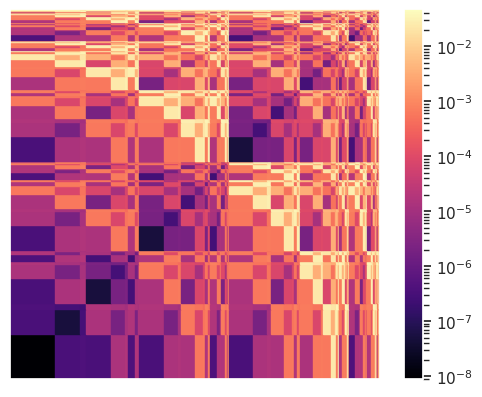

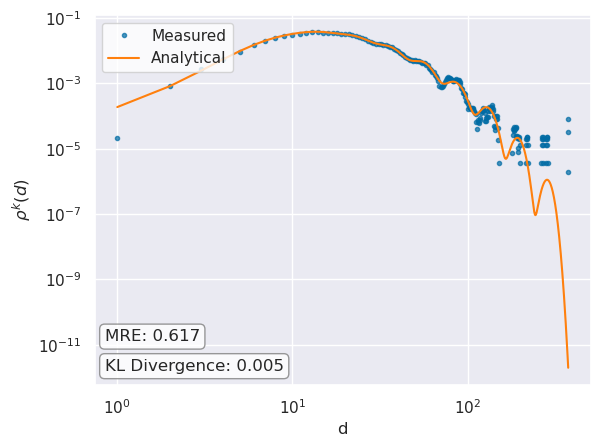

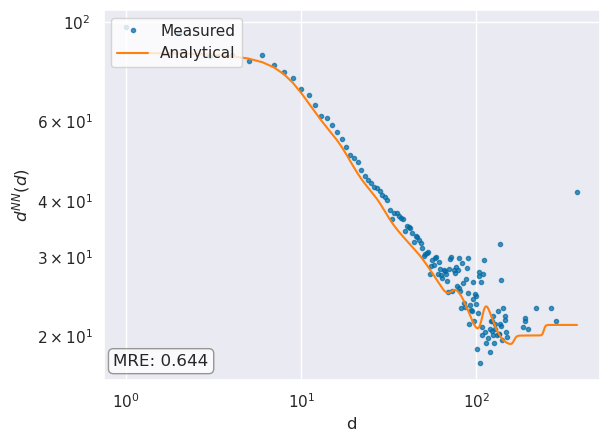

Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:11.419347
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:12:15.360420


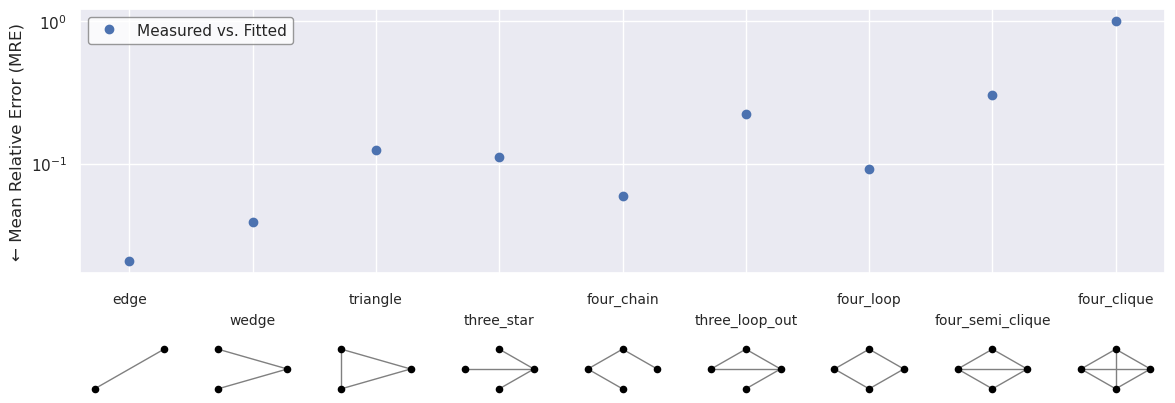

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'analytical_count': 130603.28824809701,
  'count': 133365,
  'MRE': 0.020707920008270424},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'analytical_count': 5119232.830449448,
  'count': 5326342,
  'MRE': 0.038883941277250325},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'analytical_count': 1332.0445895672015,
  'count': 1521,
  'MRE': 0.12423103907481824},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'analytical_count': 101951717.60639928,
  'count': 114630768,
  'MRE': 0.11060774183769508},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'analytical_count': 161590725.46722203,
  'count': 171695

In [8]:
#generator.plot_generated_network(
#    layout_func = nx.spring_layout,
#    largest_component_only = False,
#)

generator.network_stats(
    log_scale = True,
    filename="figures/synthetic_network_10k_plot_ground_truth.pdf",
    motif_analyzer_args = {
        'exact': True,
        'bootstrap_iters': None,
        'ci': None
    }
)

generator.motifs

In [9]:
generator.save_network('./test_networks/synthetic_network_10k.graphml')

---

# Fitting

## Load, count motifs

In [4]:
filename = './test_networks/synthetic_network_10k.graphml'
G = nx.read_graphml(filename)

In [5]:
for m_size in [2,3,5]:
    print(m_size,' k_max: ',int(np.log(len(G))/np.log(m_size**2))+1)

2  k_max:  7
3  k_max:  5
5  k_max:  3


In [6]:
mfnf = MultifractalNetworkFitter(G,
                                 #d_range = [1,200],
                                 motifs = [
                                     {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
                                     {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
                                     {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
                                     {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
                                 ],
                                 sampling_ratios = {3: None,
                                                    4: None},
                                 motif_analyzer_args={'exact': True, 'bootstrap_iters': None, 'ci': None},
                                 population_size = 100,
                                 weights = {'rho':9,
                                            'deg_nn':9,
                                            'motifs':1,
                                            'edge':9},
                                 pre_loaded_motifs = './test_networks/synthetic_network_10k_motifs.pkl'
                                )

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Succesfully loaded motifs for network G from ./test_networks/synthetic_network_10k_motifs.pkl


In [7]:
P = np.array([
    [0.28496249, 0.46450071, 0.3449749 ],
    [0.46450071, 0.00946877, 0.39117118],
    [0.34497490, 0.39117118, 0.05582052]
])
l = np.array(
    [0.08283585, 0.59124287, 0.32592127]
)
k = 4
mfnf.set_ground_truth(P = P, l = l, k = k)

In [13]:
mfnf.save_motifs('./test_networks/synthetic_network_10k_motifs.pkl')

## Grid Search - Find m,k,P,l together

In [8]:
mfnf.find_m_k_P_l(
    m_k_dict = [{'m': 2,   'k': [1,7]},
                {'m': 3,   'k': [1,5]},
                {'m': 5,   'k': [1,3]},
               ],
    n_trials = None,
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = False,
    grid_search = True,
    optimize_for = 'kl_energy'
)

[I 2025-02-14 20:00:36,356] A new study created in memory with name: no-name-24386e7e-45b9-4953-8e72-d7ab342e031f


Grid Search requires 6 trials...


[I 2025-02-14 20:00:47,253] Trial 0 finished with value: 5.490407050873299 and parameters: {'m': 2, 'k': 6}. Best is trial 0 with value: 5.490407050873299.
[I 2025-02-14 20:00:56,650] Trial 1 finished with value: 6.860921901457557 and parameters: {'m': 2, 'k': 3}. Best is trial 0 with value: 5.490407050873299.
[I 2025-02-14 20:01:06,589] Trial 2 finished with value: 8.270829314672488 and parameters: {'m': 2, 'k': 2}. Best is trial 0 with value: 5.490407050873299.
[I 2025-02-14 20:01:16,349] Trial 3 finished with value: 5.636292457567227 and parameters: {'m': 2, 'k': 4}. Best is trial 0 with value: 5.490407050873299.
[I 2025-02-14 20:01:26,067] Trial 4 finished with value: 36.17457357400733 and parameters: {'m': 2, 'k': 1}. Best is trial 0 with value: 5.490407050873299.
[I 2025-02-14 20:01:36,464] Trial 5 finished with value: 5.516627008835331 and parameters: {'m': 2, 'k': 5}. Best is trial 0 with value: 5.490407050873299.
[I 2025-02-14 20:01:36,466] A new study created in memory with n

Grid Search requires 4 trials...


[I 2025-02-14 20:01:53,980] Trial 0 finished with value: 5.088305686500959 and parameters: {'m': 3, 'k': 3}. Best is trial 0 with value: 5.088305686500959.
[I 2025-02-14 20:02:13,177] Trial 1 finished with value: 4.563374859786271 and parameters: {'m': 3, 'k': 4}. Best is trial 1 with value: 4.563374859786271.
[I 2025-02-14 20:02:25,503] Trial 2 finished with value: 6.190733122653968 and parameters: {'m': 3, 'k': 2}. Best is trial 1 with value: 4.563374859786271.
[I 2025-02-14 20:02:36,554] Trial 3 finished with value: 14.839734024464812 and parameters: {'m': 3, 'k': 1}. Best is trial 1 with value: 4.563374859786271.
[I 2025-02-14 20:02:36,555] A new study created in memory with name: no-name-8ff0c29a-afdd-484e-bcca-0af4a5857e0d


Grid Search requires 2 trials...


[I 2025-02-14 20:03:17,574] Trial 0 finished with value: 5.400813937797751 and parameters: {'m': 5, 'k': 2}. Best is trial 0 with value: 5.400813937797751.
[I 2025-02-14 20:03:29,122] Trial 1 finished with value: 40.41925300211637 and parameters: {'m': 5, 'k': 1}. Best is trial 0 with value: 5.400813937797751.


Best parameters:  {'m': 3, 'k': 4}
Best energy:  10.445678787767896
Best KL-divergence:  0.09852401401136858
Best KLD augumented energy: 4.563374859786271
Best P matrix:
 [[1.97046419e-05 5.01027617e-01 1.62910757e-01]
 [5.01027617e-01 2.44229635e-01 9.57572959e-02]
 [1.62910757e-01 9.57572959e-02 4.17344419e-01]]
Best l vector:
 [0.48300494 0.28664202 0.23035303]


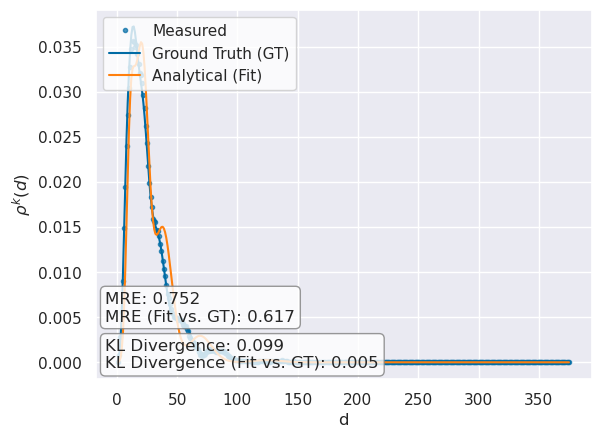

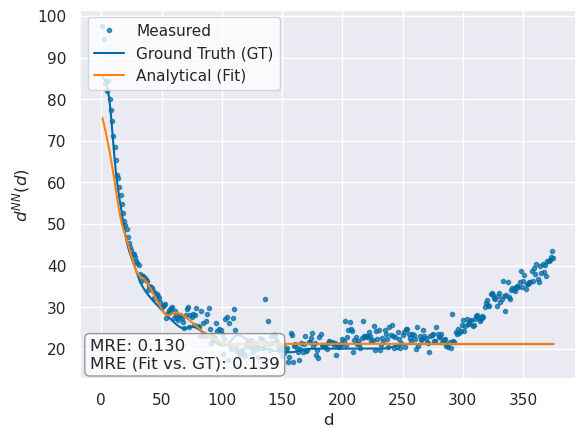

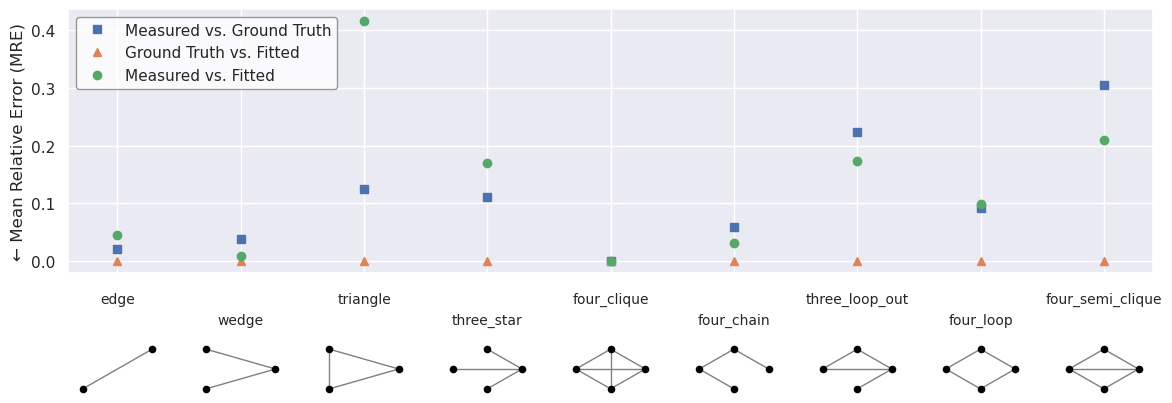

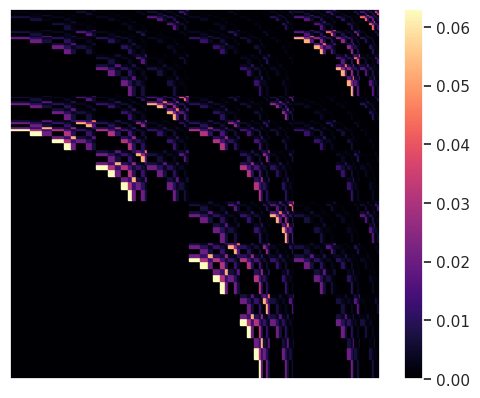

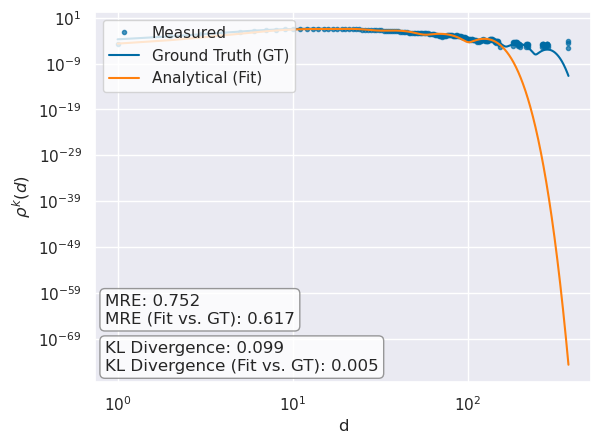

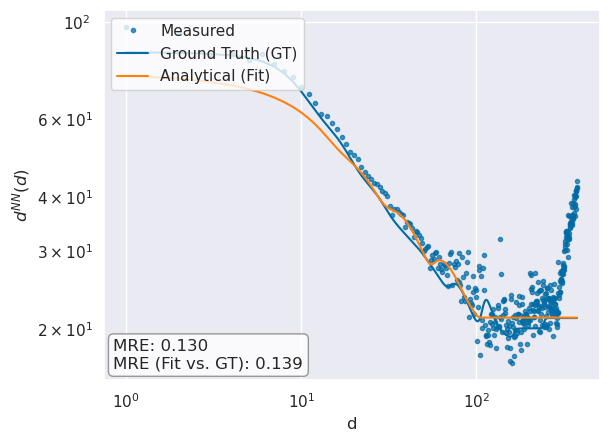

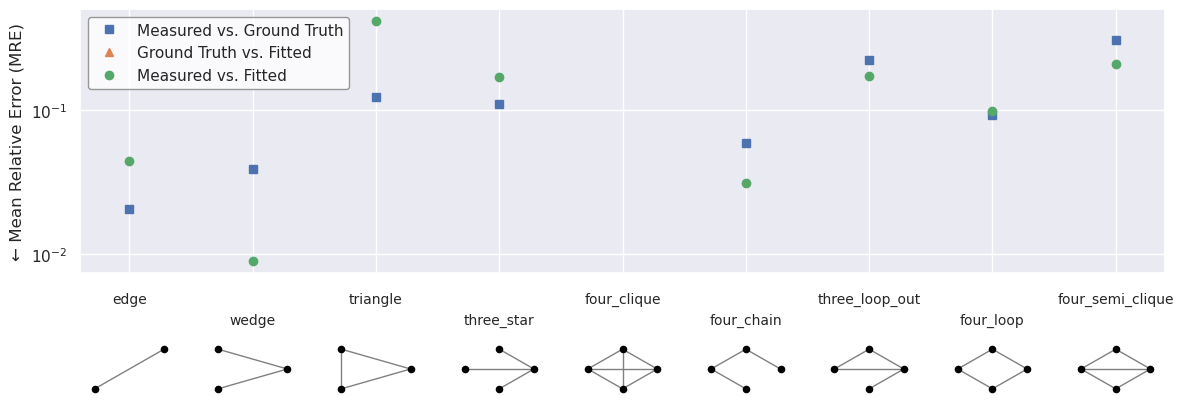

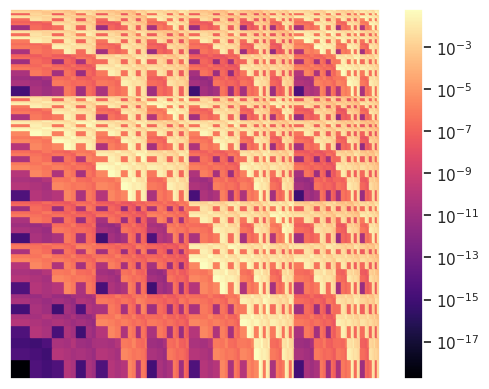

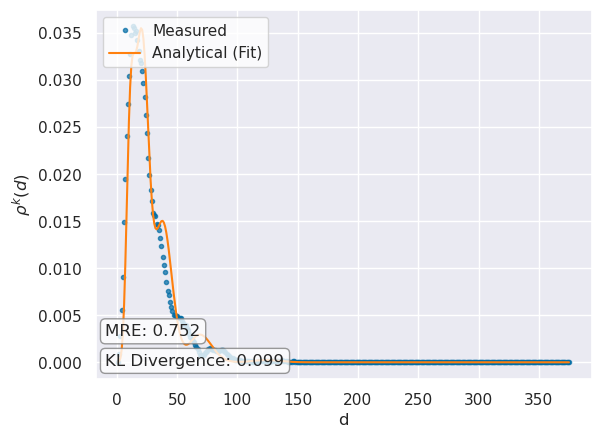

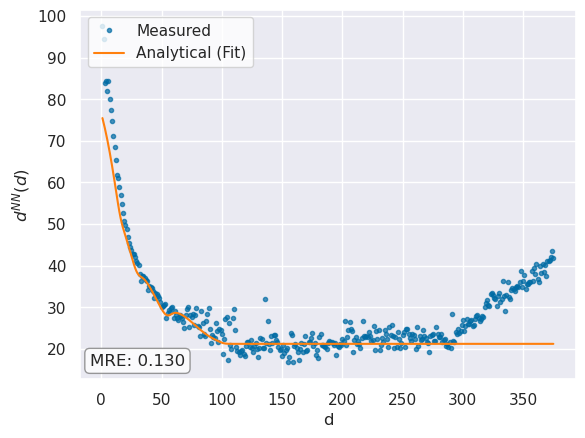

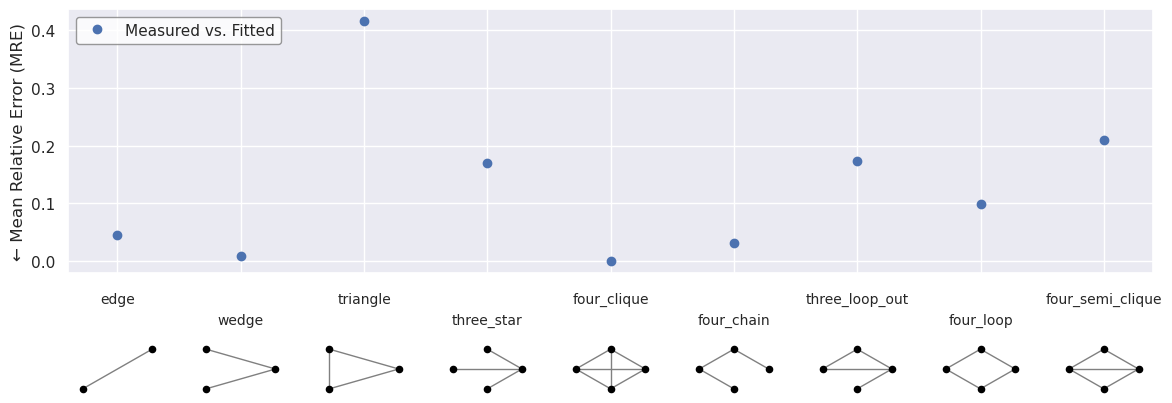

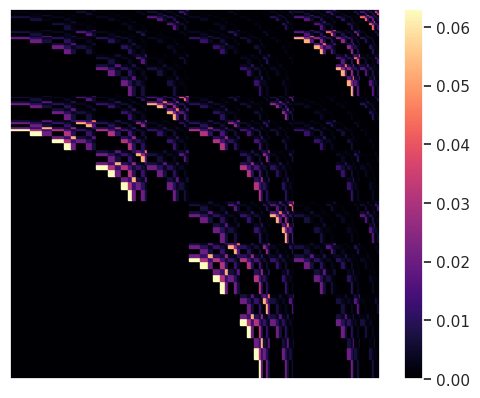

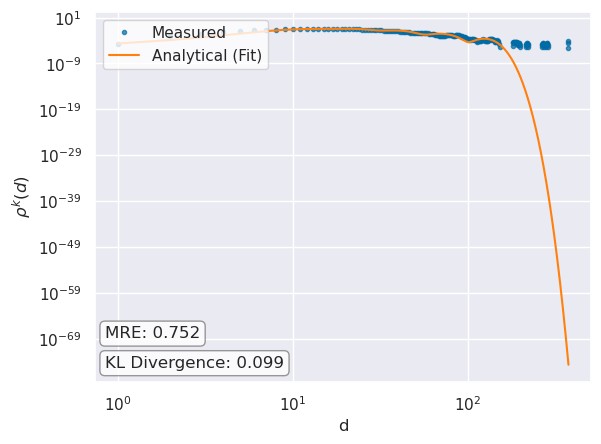

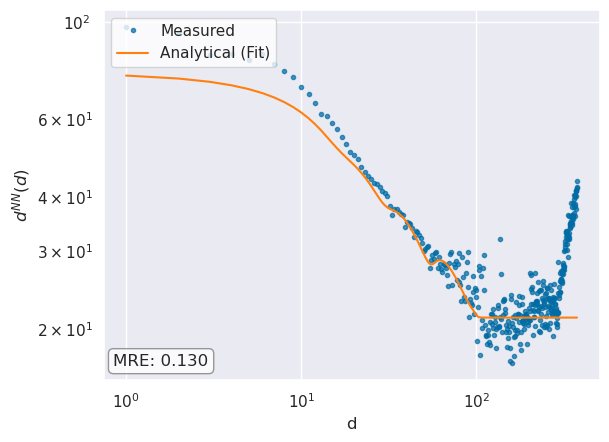

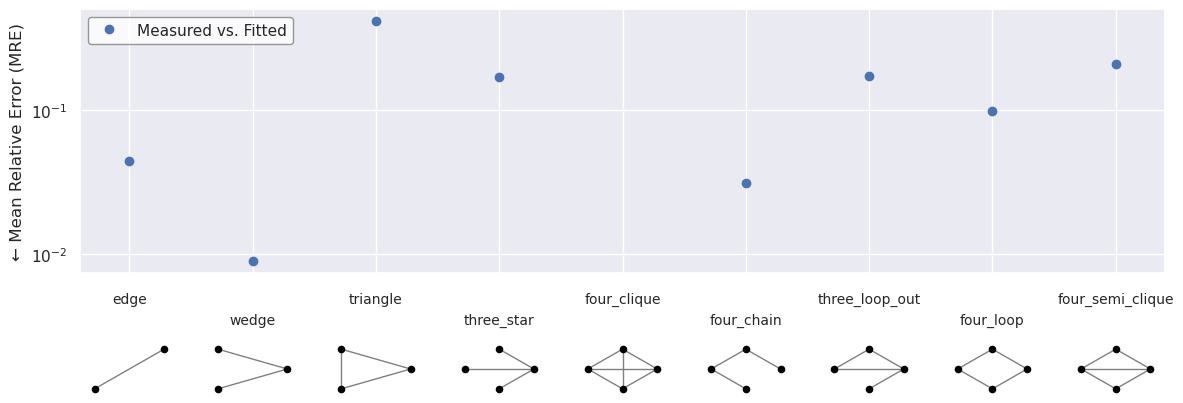

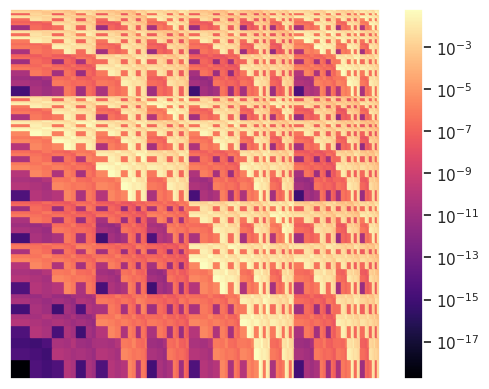

In [9]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_ground_truth=True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_10k_plot_gt.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_ground_truth=True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_10k_log_plot_gt.pdf"
)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_ground_truth=False,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_10k_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_ground_truth=False,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_10k_log_plot.pdf"
)

In [10]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 133365,
  'ground_truth_analytical': 130603,
  'ground_truth_MRE': 0.020710081355678027,
  'expected_count': 139536,
  'MRE': 0.04422514619883041},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 5326342,
  'ground_truth_analytical': 5119232,
  'ground_truth_MRE': 0.038884097190905124,
  'expected_count': 5374727,
  'MRE': 0.009002317699112904},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 1521,
  'ground_truth_analytical': 1332,
  'ground_truth_MRE': 0.1242603550295858,
  'expected_count': 2603,
  'MRE': 0.4156742220514791},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 114630768,
  'ground_truth_analytical': 101951701,
  'ground_truth_MRE': 0.1106078867062

---

## Bootstrapping stability

In [11]:
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size * 10,
    ci = 0.95,
    medoid = 'mean'
)

Gathering statistics (300 runs)...


100%|██████████| 300/300 [1:37:51<00:00, 19.57s/it]

Bootstrapping: Resampling 1000 times...


Bootstrapping finished in 0:00:00.464337
Energy = 10.11 (8.56, 11.13)
l = [0.61 (0.42, 0.75), 0.28 (0.17, 0.43), 0.10 (0.00, 0.25)]
P = [
[0.06 (0.00, 0.15), 0.36 (0.12, 0.49), 0.44 (0.06, 0.81)],

[0.36 (0.12, 0.49), 0.15 (0.00, 0.37), 0.31 (0.00, 0.90)],

[0.44 (0.06, 0.81), 0.31 (0.00, 0.90), 0.36 (0.00, 0.98)]
]


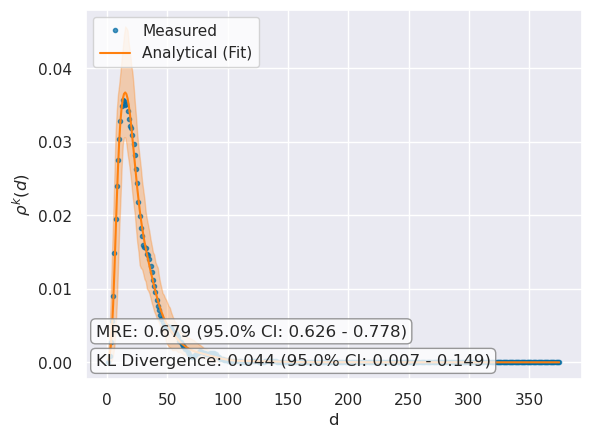

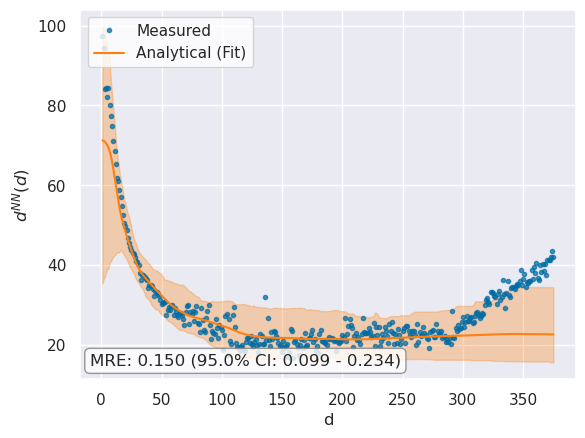

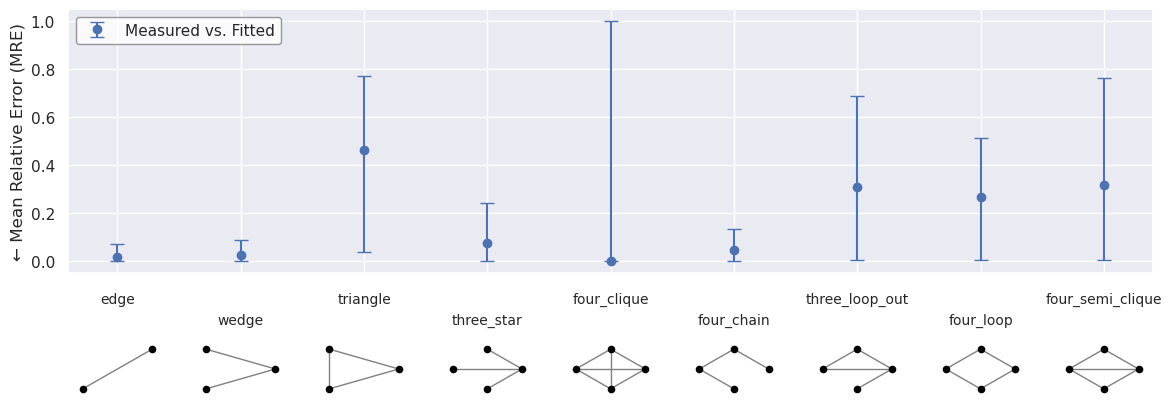

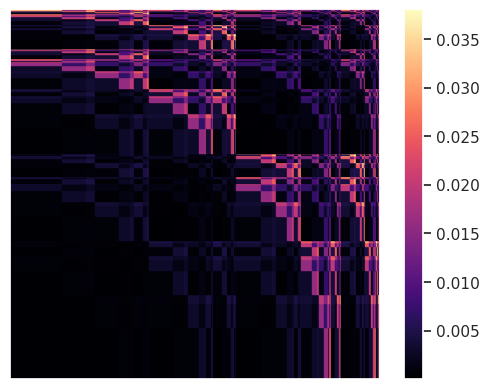

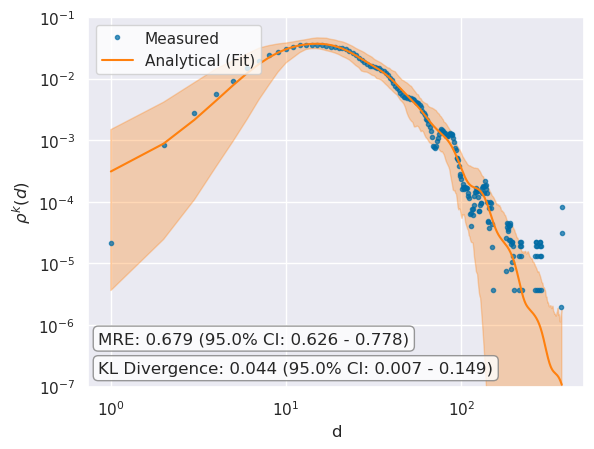

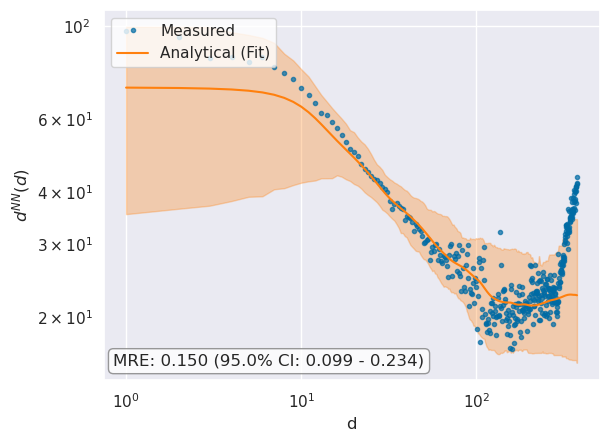

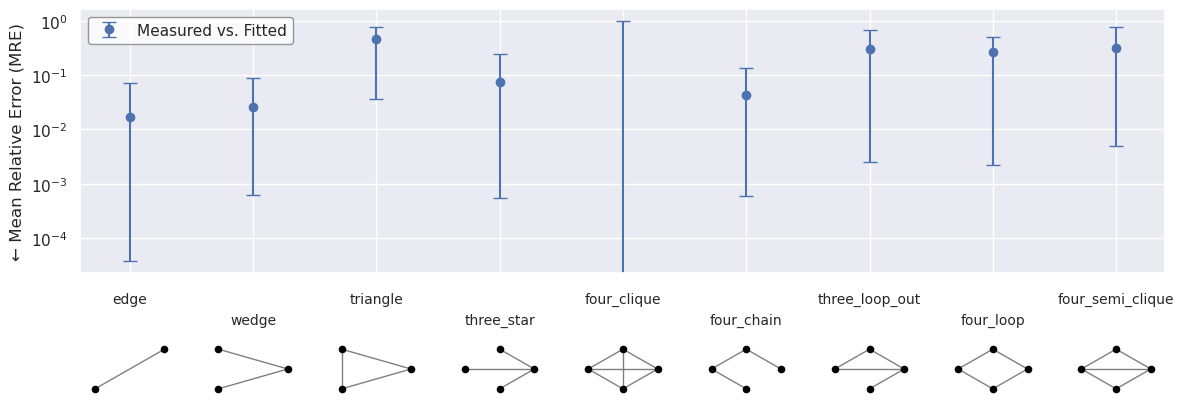

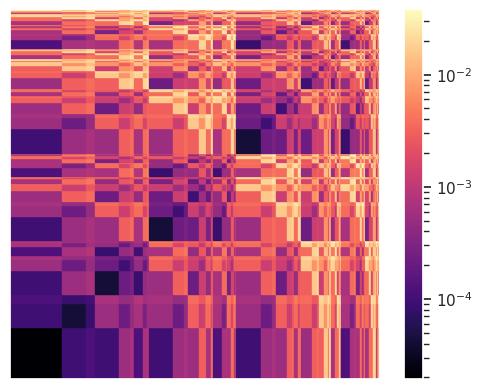

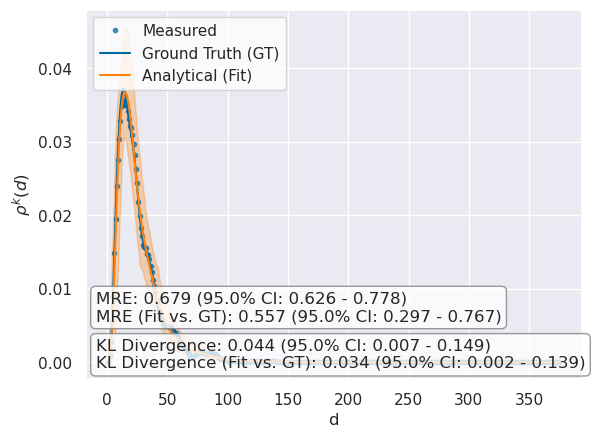

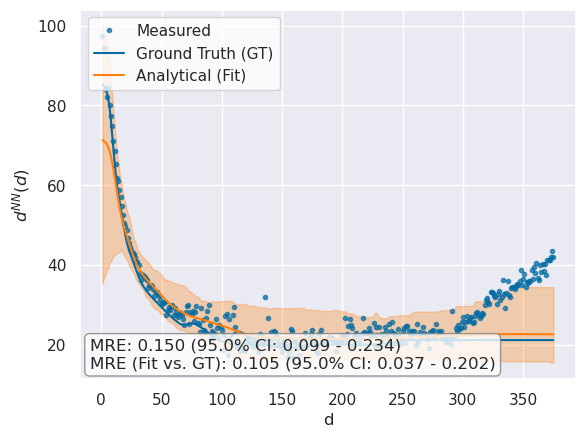

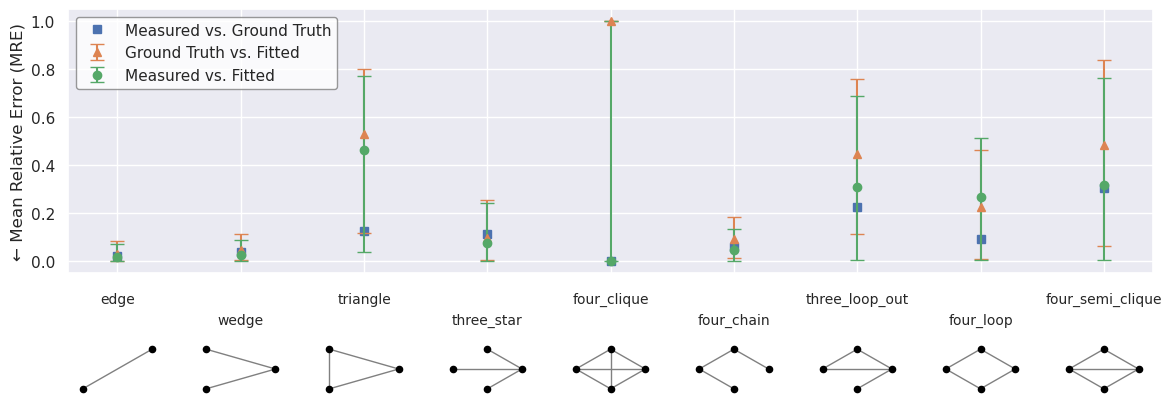

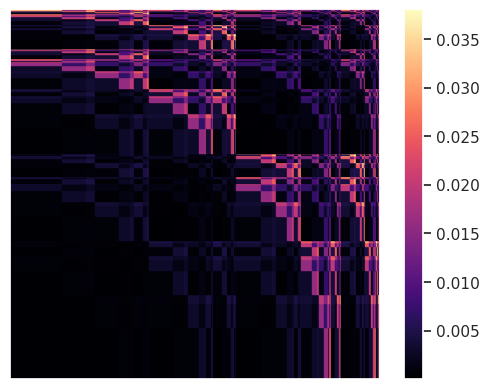

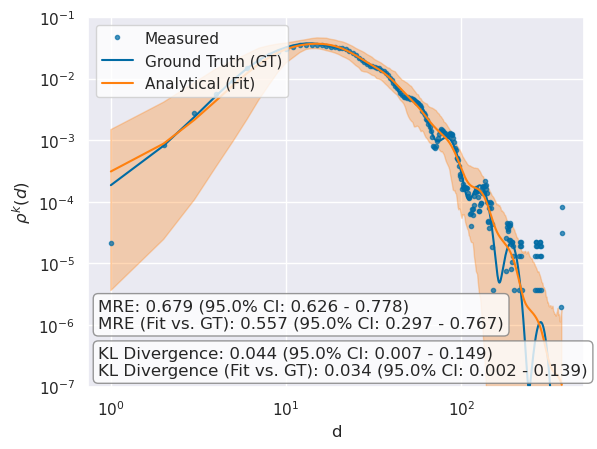

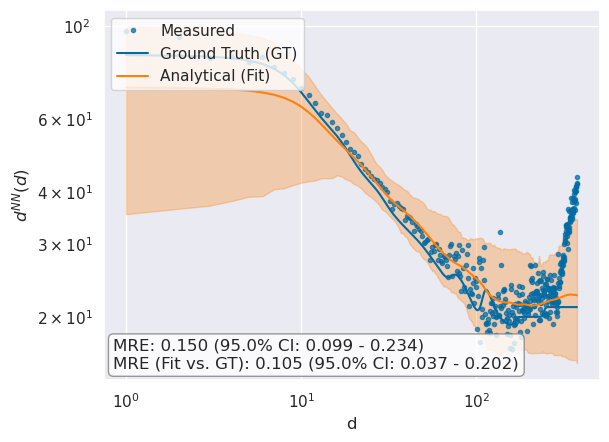

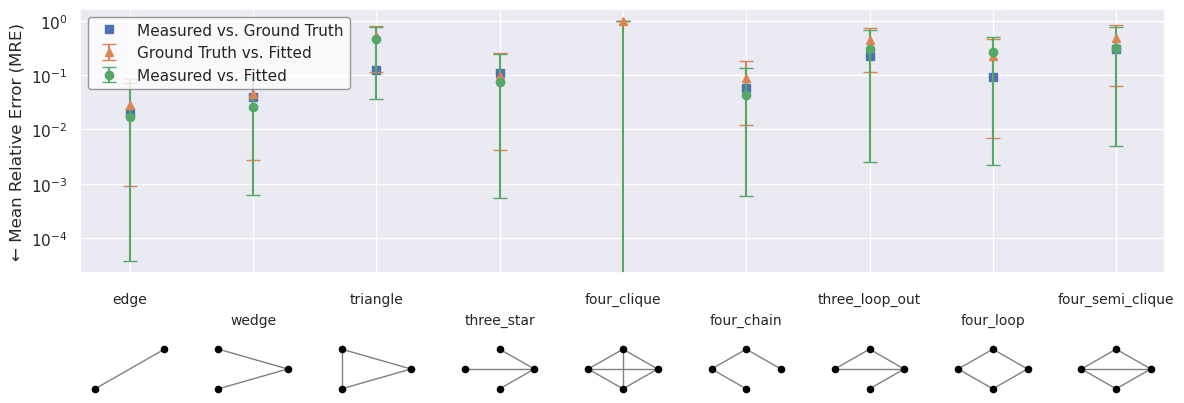

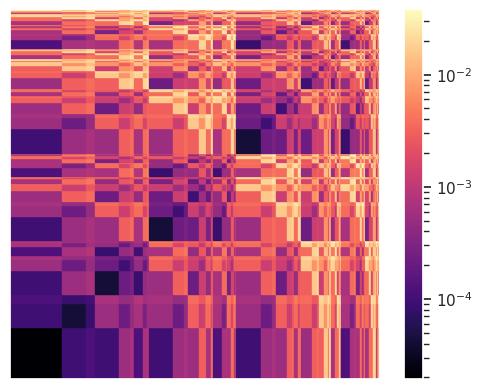

In [16]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_10k_plot_bootstrap.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    ylim=(1e-7,1e-1),
    filename = "figures/synthetic_network_10k_log_plot_bootstrap.pdf"
)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_ground_truth=True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_10k_plot_bootstrap_gt.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_ground_truth=True,
    plot_cumulative_error = False,
    ylim=(1e-7,1e-1),
    filename = "figures/synthetic_network_10k_log_plot_bootstrap_gt.pdf"
)

In [13]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 133365,
  'ground_truth_analytical': 130603,
  'ground_truth_MRE': 0.020710081355678027,
  'expected_count': 136743.0,
  'MRE': 0.0171204244297804,
  'fit_ground_truth_MRE': 0.028024248435699426,
  'expected_count_ci_low': 136743.0,
  'expected_count_ci_high': 136743.0,
  'MRE_ci_low': 3.748969033515783e-05,
  'MRE_ci_high': 0.07072409219895605,
  'fit_ground_truth_MRE_ci_low': 0.0009111582429193817,
  'fit_ground_truth_MRE_ci_high': 0.08453488290586908},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 5326342,
  'ground_truth_analytical': 5119232,
  'ground_truth_MRE': 0.038884097190905124,
  'expected_count': 5555021.0,
  'MRE': 0.026482437939811972,
  'fit_ground_truth_MRE': 0.045414141463640915,
  'expected_count_ci_low': 5555021.0,
  'expected_count_ci_high': 5555021.0,
  'MRE_ci_low': 0.0006186234379992873,
  'MRE_ci_high': 0.0

In [17]:
import pickle
with open('./test_networks/synthetic_network_10k_mfnf.pkl', 'wb') as f:
    pickle.dump(mfnf, f)